<a href="https://colab.research.google.com/github/Venom-Ocelot/adaptive-resolution-steel-defect-segmentation/blob/For-Large-U-Net/Large_Unet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!nvidia-smi
!pip -q install segmentation-models-pytorch albumentations kaggle

Mon Oct 26 20:36:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   64C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import os, json, shutil
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/CSCI6379_Team11'
CKPT_DIR    = f'{PROJECT_DIR}/checkpoints/large_unet'
RESULTS_DIR = f'{PROJECT_DIR}/results/large_unet'
DATA_DIR    = '/content/severstal'
for d in (CKPT_DIR, RESULTS_DIR): os.makedirs(d, exist_ok=True)

Mounted at /content/drive


In [ ]:
if not os.path.exists('/root/.kaggle/kaggle.json'):
    from google.colab import files
    files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)

Saving kaggle.json to kaggle.json


In [ ]:
if not os.path.exists(f'{DATA_DIR}/train.csv'):
    !kaggle competitions download -c severstal-steel-defect-detection -p /content
    !mkdir -p {DATA_DIR} && unzip -q -o /content/severstal-steel-defect-detection.zip -d {DATA_DIR}
print(os.listdir(DATA_DIR))

100% 1.57G/1.57G [00:18<00:00, 92.6MB/s]

['train.csv', 'train_images', 'sample_submission.csv', 'test_images']


In [ ]:
import numpy as np, pandas as pd
train_csv = pd.read_csv(f'{DATA_DIR}/train.csv')
all_ids = sorted(os.listdir(f'{DATA_DIR}/train_images'))
img_df = pd.DataFrame({'ImageId': all_ids})
for c in range(1, 5):
    rle = train_csv[train_csv.ClassId == c].set_index('ImageId')['EncodedPixels']
    img_df[f'rle_{c}'] = img_df.ImageId.map(rle)
img_df['classes'] = img_df.apply(
    lambda r: ''.join(str(c) for c in range(1, 5) if isinstance(r[f'rle_{c}'], str)) or '0', axis=1)
print(len(img_df), 'images |', (img_df.classes != '0').sum(), 'with defects')
print(img_df.classes.value_counts())


12568 images | 6666 with defects
classes
0      5902
3      4759
1       769
4       516
34      284
2       195
13       91
12       35
23       14
123       2
24        1
Name: count, dtype: int64


In [ ]:
H, W = 256, 1600
def rle_decode(rle, shape=(H, W)):
    m = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str):
        s = np.asarray(rle.split(), dtype=int)
        for start, length in zip(s[0::2] - 1, s[1::2]):
            m[start:start + length] = 1
    return m.reshape(shape, order='F')

def rle_encode(mask):
    p = np.concatenate([[0], mask.flatten(order='F'), [0]])
    runs = np.where(p[1:] != p[:-1])[0] + 1
    runs[1::2] -= runs[0::2]
    return ' '.join(map(str, runs))

ex = train_csv.EncodedPixels.iloc[0]
assert rle_encode(rle_decode(ex)) == ex, 'RLE round trip failed'
print('RLE decode OK')

RLE decode OK


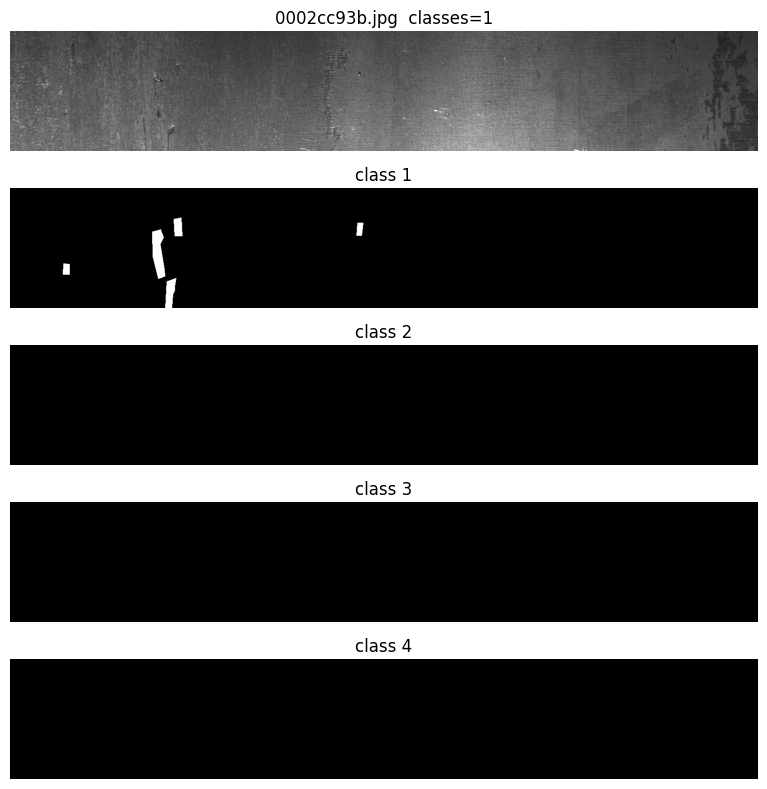

In [ ]:
import cv2, matplotlib.pyplot as plt
r = img_df[img_df.classes != '0'].iloc[0]
img = cv2.cvtColor(cv2.imread(f'{DATA_DIR}/train_images/{r.ImageId}'), cv2.COLOR_BGR2RGB)
fig, ax = plt.subplots(5, 1, figsize=(14, 8))
ax[0].imshow(img); ax[0].set_title(f'{r.ImageId}  classes={r.classes}')
for c in range(1, 5):
    ax[c].imshow(rle_decode(r[f'rle_{c}']), cmap='gray'); ax[c].set_title(f'class {c}')
for a in ax: a.axis('off')
plt.tight_layout()

In [ ]:
from sklearn.model_selection import train_test_split
SPLIT_PATH = f'{PROJECT_DIR}/splits.csv'
if os.path.exists(SPLIT_PATH):
    split_df = pd.read_csv(SPLIT_PATH); print('Loaded existing team split')
else:
    counts = img_df.classes.map(img_df.classes.value_counts())
    strat = img_df.classes.where(counts >= 20, 'rare')
    tr_idx, tmp_idx = train_test_split(img_df.index, test_size=0.30, stratify=strat, random_state=42)
    va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, stratify=strat.loc[tmp_idx], random_state=42)
    split_df = pd.DataFrame({'ImageId': img_df.ImageId, 'split': 'train'})
    split_df.loc[va_idx, 'split'] = 'val'; split_df.loc[te_idx, 'split'] = 'test'
    split_df.to_csv(SPLIT_PATH, index=False); print('Created and saved new split -> share it!')
img_df = img_df.drop(columns='split', errors='ignore').merge(split_df, on='ImageId')
print(pd.crosstab(img_df.classes, img_df.split, margins=True))

Created and saved new split -> share it!
split    test  train   val    All
classes                          
0         886   4131   885   5902
1         116    538   115    769
12          5     25     5     35
123         0      1     1      2
13         13     64    14     91
2          29    136    30    195
23          2     10     2     14
24          0      1     0      1
3         714   3331   714   4759
34         43    199    42    284
4          78    361    77    516
All      1886   8797  1885  12568


In [ ]:
import torch, albumentations as A
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)
CROP_W = 800

train_tf = A.Compose([
    A.RandomCrop(height=H, width=CROP_W),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.5),
])

class SteelDataset(Dataset):
    def __init__(self, df, tf=None):
        self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        img = cv2.cvtColor(cv2.imread(f'{DATA_DIR}/train_images/{r.ImageId}'), cv2.COLOR_BGR2RGB)
        mask = np.stack([rle_decode(r[f'rle_{c}']) for c in range(1, 5)], axis=-1)
        if self.tf is not None:
            out = self.tf(image=img, mask=mask); img, mask = out['image'], out['mask']
        img = (img.astype(np.float32) / 255.0 - MEAN) / STD
        return (torch.from_numpy(img.transpose(2, 0, 1).copy()),
                torch.from_numpy(mask.transpose(2, 0, 1).copy()).float(), r.ImageId)

train_df = img_df[img_df.split == 'train']
val_df   = img_df[img_df.split == 'val']
test_df  = img_df[img_df.split == 'test']

DEFECT_WEIGHT = 2.0
w = np.where(train_df.classes != '0', DEFECT_WEIGHT, 1.0)
sampler = WeightedRandomSampler(w, num_samples=len(w))

In [ ]:
import segmentation_models_pytorch as smp
NUM_CLASSES = 4
model = smp.Unet(encoder_name='resnet34', encoder_weights='imagenet', classes=NUM_CLASSES).cuda()
print(f'{sum(p.numel() for p in model.parameters())/1e6:.1f}M parameters')

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

24.4M parameters


In [ ]:
train_ds = SteelDataset(train_df, tf=train_tf)
val_ds   = SteelDataset(val_df)

train_dl = DataLoader(train_ds, batch_size=8, sampler=sampler, num_workers=2, drop_last=True)
val_dl   = DataLoader(val_ds, batch_size=8, shuffle=False, num_workers=2)

x, y, ids = next(iter(train_dl))
with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
    out = model(x.cuda())
print('input', tuple(x.shape), '| mask', tuple(y.shape), '| output', tuple(out.shape))
print(f'GPU memory used: {torch.cuda.memory_allocated()/1e9:.2f} GB')

input (8, 3, 256, 800) | mask (8, 4, 256, 800) | output (8, 4, 256, 800)
GPU memory used: 0.11 GB


In [ ]:
EPOCHS, LR = 30, 3e-4
bce = torch.nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode='multilabel', from_logits=True)
def loss_fn(logits, y): return bce(logits, y) + dice_loss(logits, y)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
scaler = torch.amp.GradScaler('cuda')

In [ ]:
THRS = np.array([0.2, 0.3, 0.4, 0.5, 0.6])
MIN_AREAS = np.array([0, 250, 500, 1000, 2000, 3000])

@torch.no_grad()
def collect_stats(model, loader):
    model.eval()
    t = torch.tensor(THRS, device='cuda', dtype=torch.float32).view(1, 1, -1, 1, 1)
    inter, parea, garea, ids = [], [], [], []
    for x, y, i in loader:
        with torch.autocast('cuda', dtype=torch.float16):
            p = torch.sigmoid(model(x.cuda(non_blocking=True))).float()
        yb = y.cuda().bool()
        pb = p.unsqueeze(2) > t
        inter.append((pb & yb.unsqueeze(2)).sum((-1, -2)).cpu())
        parea.append(pb.sum((-1, -2)).cpu())
        garea.append(yb.sum((-1, -2)).cpu())
        ids += list(i)
    return {'inter': torch.cat(inter).numpy(), 'parea': torch.cat(parea).numpy(),
            'garea': torch.cat(garea).numpy(), 'ids': ids}

def per_image(S, thr_idx, min_area):
    c = np.arange(4)
    inter = S['inter'][:, c, thr_idx].astype(float)
    parea = S['parea'][:, c, thr_idx].astype(float)
    garea = S['garea'].astype(float)
    keep = parea >= np.asarray(min_area)
    return inter * keep, parea * keep, garea

def metrics(S, thr_idx=(3, 3, 3, 3), min_area=(0, 0, 0, 0)):
    inter, parea, garea = per_image(S, np.asarray(thr_idx), min_area)
    empty = (parea == 0) & (garea == 0)
    dice = np.where(empty, 1.0, 2 * inter / np.maximum(parea + garea, 1))
    iou  = np.where(empty, 1.0, inter / np.maximum(parea + garea - inter, 1))
    gpos, ppos = garea > 0, parea > 0
    img_g, img_p = gpos.any(1), ppos.any(1)
    out = {
        'dice_kaggle': dice.mean(),
        'dice_defect': dice[gpos].mean(),
        'miou_kaggle': iou.mean(),
        'miou_defect': iou[gpos].mean(),
        'img_recall':  (img_g & img_p).sum() / max(img_g.sum(), 1),
        'img_FN':      int((img_g & ~img_p).sum()),
        'img_FPR':     (~img_g & img_p).sum() / max((~img_g).sum(), 1),
    }
    for k in range(4):
        out[f'recall_c{k+1}'] = (gpos[:, k] & ppos[:, k]).sum() / max(gpos[:, k].sum(), 1)
        out[f'dice_c{k+1}'] = dice[:, k].mean()
    return out

In [ ]:
from tqdm.auto import tqdm
LAST, BEST = f'{CKPT_DIR}/last.pth', f'{CKPT_DIR}/best.pth'
LOG = f'{RESULTS_DIR}/train_log.csv'
start_epoch, best_score = 0, -1.0
if os.path.exists(LAST):
    ck = torch.load(LAST, map_location='cuda', weights_only=False)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
    sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
    start_epoch, best_score = ck['epoch'] + 1, ck['best']
    print(f'Resuming at epoch {start_epoch}, best val dice_defect {best_score:.4f}')

for epoch in range(start_epoch, EPOCHS):
    model.train(); run = 0.0
    for x, y, _ in tqdm(train_dl, desc=f'epoch {epoch}', leave=False):
        x, y = x.cuda(non_blocking=True), y.cuda(non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast('cuda', dtype=torch.float16):
            loss = loss_fn(model(x), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        run += loss.item()
    sched.step()

    m = metrics(collect_stats(model, val_dl))
    row = {'epoch': epoch, 'train_loss': run / len(train_dl), 'lr': sched.get_last_lr()[0], **m}
    pd.DataFrame([row]).to_csv(LOG, mode='a', header=not os.path.exists(LOG), index=False)
    print({k: round(float(v), 4) for k, v in row.items()})

    if m['dice_defect'] > best_score:
        best_score = m['dice_defect']; torch.save(model.state_dict(), BEST)
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                'scaler': scaler.state_dict(), 'epoch': epoch, 'best': best_score}, LAST)

epoch 0:   0%|          | 0/1099 [00:00<?, ?it/s]

{'epoch': 0.0, 'train_loss': 0.4393, 'lr': 0.0003, 'dice_kaggle': 0.82, 'dice_defect': 0.3912, 'miou_kaggle': 0.807, 'miou_defect': 0.2991, 'img_recall': 0.792, 'img_FN': 208.0, 'img_FPR': 0.5232, 'recall_c1': 0.0, 'dice_c1': 0.9284, 'recall_c2': 0.0, 'dice_c2': 0.9798, 'recall_c3': 0.8241, 'dice_c3': 0.607, 'recall_c4': 0.9496, 'dice_c4': 0.7647}


epoch 1:   0%|          | 0/1099 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f77add60860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f77add60860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

{'epoch': 1.0, 'train_loss': 0.3448, 'lr': 0.0003, 'dice_kaggle': 0.6382, 'dice_defect': 0.5308, 'miou_kaggle': 0.6208, 'miou_defect': 0.4072, 'img_recall': 0.981, 'img_FN': 19.0, 'img_FPR': 0.7774, 'recall_c1': 0.963, 'dice_c1': 0.2757, 'recall_c2': 0.0, 'dice_c2': 0.9729, 'recall_c3': 0.9664, 'dice_c3': 0.5197, 'recall_c4': 0.9328, 'dice_c4': 0.7845}


epoch 2:   0%|          | 0/1099 [00:00<?, ?it/s]

... (51 outputs left out)

epoch 28:   0%|          | 0/1099 [00:00<?, ?it/s]

{'epoch': 28.0, 'train_loss': 0.183, 'lr': 0.0, 'dice_kaggle': 0.8633, 'dice_defect': 0.6724, 'miou_kaggle': 0.8457, 'miou_defect': 0.5478, 'img_recall': 0.988, 'img_FN': 12.0, 'img_FPR': 0.2497, 'recall_c1': 0.963, 'dice_c1': 0.8466, 'recall_c2': 0.8947, 'dice_c2': 0.9031, 'recall_c3': 0.9767, 'dice_c3': 0.7816, 'recall_c4': 0.9748, 'dice_c4': 0.9218}


epoch 29:   0%|          | 0/1099 [00:00<?, ?it/s]

{'epoch': 29.0, 'train_loss': 0.18, 'lr': 0.0, 'dice_kaggle': 0.8379, 'dice_defect': 0.6724, 'miou_kaggle': 0.8201, 'miou_defect': 0.5464, 'img_recall': 0.995, 'img_FN': 5.0, 'img_FPR': 0.304, 'recall_c1': 0.9704, 'dice_c1': 0.7837, 'recall_c2': 0.9737, 'dice_c2': 0.8727, 'recall_c3': 0.978, 'dice_c3': 0.7803, 'recall_c4': 0.9916, 'dice_c4': 0.9151}


In [ ]:
RECALL_TARGET = 0.95   # agree this number with the team; the small U-Net must use the same
model.load_state_dict(torch.load(BEST, map_location='cuda'))
S_val = collect_stats(model, val_dl)

def tune(S, target):
    thr_idx, min_area = np.zeros(4, int), np.zeros(4, int)
    for k in range(4):
        best = None
        for ti in range(len(THRS)):
            for ma in MIN_AREAS:
                ma4 = np.zeros(4); ma4[k] = ma
                m = metrics(S, np.full(4, ti), ma4)
                rec, d = m[f'recall_c{k+1}'], m[f'dice_c{k+1}']
                key = (rec >= target, d if rec >= target else rec)
                if best is None or key > best[0]: best = (key, ti, ma)
        thr_idx[k], min_area[k] = best[1], best[2]
    return thr_idx, min_area

thr_idx, min_area = tune(S_val, RECALL_TARGET)
print('per-class thresholds:', THRS[thr_idx], '| min areas:', min_area)
json.dump({'thresholds': THRS[thr_idx].tolist(), 'min_area': min_area.tolist(),
           'recall_target': RECALL_TARGET}, open(f'{RESULTS_DIR}/tuned_thresholds.json', 'w'), indent=2)

per-class thresholds: [0.6 0.2 0.4 0.6] | min areas: [   0    0 1000 3000]


In [ ]:
test_ds = SteelDataset(test_df)
test_dl = DataLoader(test_ds, batch_size=8, shuffle=False, num_workers=2)

def full_report(S, thr_idx, min_area):
    m = metrics(S, thr_idx, min_area)
    inter, parea, garea = per_image(S, np.asarray(thr_idx), min_area)
    gpos, ppos = garea > 0, parea > 0
    g, p = gpos.any(1), ppos.any(1)
    TP, FN, FP, TN = (g & p).sum(), (g & ~p).sum(), (~g & p).sum(), (~g & ~p).sum()
    overall = {
        'Defect-image recall': m['img_recall'],
        'False negatives (images)': int(FN),
        'Image-level accuracy': (TP + TN) / len(g),
        'Image-level precision': TP / max(TP + FP, 1),
        'False-positive rate (defect-free images)': m['img_FPR'],
        'Dice (defect present only)': m['dice_defect'],
        'Mean IoU (defect present only)': m['miou_defect'],
        'Dice (Kaggle-style, all images)': m['dice_kaggle'],
        'Mean IoU (Kaggle-style, all images)': m['miou_kaggle'],
    }
    per_class = pd.DataFrame({
        'Class': [1, 2, 3, 4],
        'Test images with class': gpos.sum(0),
        'Recall': [m[f'recall_c{k+1}'] for k in range(4)],
        'False negatives': (gpos & ~ppos).sum(0),
        'Dice': [m[f'dice_c{k+1}'] for k in range(4)],
    })
    return pd.Series(overall), per_class

S_test = collect_stats(model, test_dl)
overall, per_class = full_report(S_test, thr_idx, min_area)
print('LARGE U-NET (ResNet34, 256x1600) - TEST SET'); print(overall.round(4).to_string())
print(); print(per_class.round(4).to_string(index=False))
overall.to_csv(f'{RESULTS_DIR}/test_overall_large.csv')
per_class.to_csv(f'{RESULTS_DIR}/test_per_class_large.csv', index=False)

# per-image results for the cascade (RQ2/RQ3)
inter, parea, garea = per_image(S_test, thr_idx, min_area)
pd.DataFrame([{'ImageId': iid, 'class': k + 1, 'inter': inter[n, k], 'pred_area': parea[n, k], 'gt_area': garea[n, k]}
              for n, iid in enumerate(S_test['ids']) for k in range(4)]
            ).to_csv(f'{RESULTS_DIR}/test_per_image_large.csv', index=False)

LARGE U-NET (ResNet34, 256x1600) - TEST SET
Defect-image recall                          0.9700
False negatives (images)                    30.0000
Image-level accuracy                         0.9062
Image-level precision                        0.8684
False-positive rate (defect-free images)     0.1659
Dice (defect present only)                   0.6625
Mean IoU (defect present only)               0.5415
Dice (Kaggle-style, all images)              0.8794
Mean IoU (Kaggle-style, all images)          0.8624

 Class  Test images with class  Recall  False negatives   Dice
     1                     134  0.9328                9 0.8507
     2                      36  0.9444                2 0.8923
     3                     772  0.9262               57 0.8162
     4                     121  0.9504                6 0.9584


In [ ]:
@torch.no_grad()
def latency_ms(model, n=200, warmup=30):
    model.eval(); x = torch.randn(1, 3, H, W, device='cuda')
    s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
    times = []
    with torch.autocast('cuda', dtype=torch.float16):
        for _ in range(warmup): model(x)
        torch.cuda.synchronize()
        for _ in range(n):
            s.record(); model(x); e.record(); torch.cuda.synchronize()
            times.append(s.elapsed_time(e))
    return float(np.median(times)), float(np.percentile(times, 95))

gpu = torch.cuda.get_device_name(0)
med, p95 = latency_ms(model)
print(f'{gpu}: large U-Net {med:.2f} ms/image (median), {p95:.2f} ms (p95)')
json.dump({'gpu': gpu, 'median_ms': med, 'p95_ms': p95},
          open(f'{RESULTS_DIR}/latency_large.json', 'w'), indent=2)

Tesla T4: large U-Net 16.23 ms/image (median), 16.58 ms (p95)
